# CareScan — train the YOLO symbol detector

Data is kept on Colab's fast local disk (`/content`); only training results go to Drive.
After a disconnect, re-run sections 1–2 before training.

Run this in **Google Colab** with a GPU: *Runtime → Change runtime type → T4 GPU*.

Steps:
1. Connect Google Drive and install packages
2. Download datasets from Roboflow and merge them
3. Split (augmented copies kept together) and check class balance
4. Train YOLOv8 (transfer learning from COCO weights)
5. Evaluate on the test set (mAP@0.5, precision, recall, confusion matrix)
6. Export the model for the app

**Before you start:** upload the whole `carescan` project folder to
`MyDrive/carescan` in Google Drive.

## 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/carescan'   # change if you put it somewhere else
%cd {PROJECT}
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
/content/drive/MyDrive/carescan
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
!pip install -q ultralytics roboflow easyocr
import ultralytics
ultralytics.checks()

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.2/112.6 GB disk)


## 2. Download datasets from Roboflow

1. Get your API key: Roboflow → Settings → API Keys. **Don't share the notebook with the key in it.**
2. For each public laundry-symbol dataset on [Roboflow Universe](https://universe.roboflow.com)
   (search "laundry symbols" / "care label"), open *Dataset → Download → YOLOv8 → show download code*
   and copy the workspace, project and version into `PUBLIC` below.
3. Put our own labelled project in `OWN`.

In [3]:
# ONE cell: download all datasets, then merge them. Re-run this whole cell after any change.
import os, sys, subprocess, yaml
from getpass import getpass
from roboflow import Roboflow

os.chdir(PROJECT)   # in case the runtime restarted

# (workspace, project, version) — fill these in, WITHOUT a # at the start of the line
PUBLIC = [
    ('wasabis-workspace', 'care-label-x5z3u-v4l3g', 1),
    ('alexander-pitkin-19mq3', 'laundry-ymnou', 10),     # v10 = bigger, augmented version
]
OWN = [
    ('wasabis-workspace', 'carescan-own-photos', 1),     # raise the version after generating a new one
]
print(f'Datasets listed: {len(PUBLIC)} public, {len(OWN)} own')
assert PUBLIC or OWN, 'PUBLIC and OWN are both empty: fill them in above'

rf = Roboflow(api_key=getpass('Roboflow API key: '))

def download(entries, folder):
    paths = []
    for ws, proj, ver in entries:
        print(f'Downloading {ws}/{proj} v{ver} ...')
        ds = rf.workspace(ws).project(proj).version(ver).download('yolov8', location=f'{folder}/{proj}_v{ver}')
        paths.append(ds.location)
    return paths

public_dirs = download(PUBLIC, '/content/downloads/public')
own_dirs = download(OWN, '/content/downloads/own')
print('\npublic:', public_dirs)
print('own:   ', own_dirs)

for d in public_dirs + own_dirs:
    names = yaml.safe_load(open(f'{d}/data.yaml'))['names']
    print(f'{d}: {len(names)} classes')

cmd = [sys.executable, 'scripts/merge_datasets.py', '--out', '/content/data/merged']
if public_dirs: cmd += ['--public', *public_dirs]
if own_dirs:    cmd += ['--own', *own_dirs]
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout, r.stderr)

Datasets listed: 2 public, 1 own
Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/downloads/public/care-label-x5z3u-v4l3g_v1 in yolov8:: 100%|██████████| 1472/1472 [00:00<00:00, 2101.36it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/downloads/public/laundry-ymnou_v10 in yolov8:: 100%|██████████| 8528/8528 [00:01<00:00, 4932.08it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/downloads/own/carescan-own-photos_v1 in yolov8:: 100%|██████████| 20/20 [00:00<00:00, 7676.95it/s]



public: ['/content/downloads/public/care-label-x5z3u-v4l3g_v1', '/content/downloads/public/laundry-ymnou_v10']
own:    ['/content/downloads/own/carescan-own-photos_v1']
/content/downloads/public/care-label-x5z3u-v4l3g_v1: 46 classes
/content/downloads/public/laundry-ymnou_v10: 74 classes
/content/downloads/own/carescan-own-photos_v1: 13 classes

Merged 4892 images into /content/data/merged
Boxes per class: {'bleach_any': 94, 'bleach_non_chlorine': 421, 'dry_drip': 108, 'dry_flat': 354, 'dry_line': 136, 'dry_shade': 197, 'dryclean_F': 120, 'dryclean_P': 2159, 'dryclean_any': 99, 'iron_high': 264, 'iron_low': 2518, 'iron_med': 1637, 'no_bleach': 4934, 'no_dryclean': 2627, 'no_iron': 1090, 'no_tumble': 3631, 'no_wash': 494, 'no_wetclean': 10, 'tumble_low': 890, 'tumble_normal': 617, 'wash_30': 1431, 'wash_30_gentle': 733, 'wash_40': 1373, 'wash_40_gentle': 710, 'wash_60': 158, 'wash_95': 114, 'wash_hand': 638, 'wetclean_W': 102}
Dropped boxes (mapped to 'drop'): {'DN_wring': 133, 'DN_ste

## 3. Split and check balance

In [4]:
!python scripts/split_dataset.py --src /content/data/merged --out /content/data/carescan
!python scripts/check_balance.py --data /content/data/carescan --min 50

4892 images from 769 original photos (4123 augmented copies, kept in the same split as their original)
Writing 4892 images to /content/data/carescan ...
  500/4892
  1000/4892
  1500/4892
  2000/4892
  2500/4892
  3000/4892
  3500/4892
  4000/4892
  4500/4892
Own photos: 9   Public images: 4883
  train:  4040 images (82.6%)  — 4 own photos
  val  :   653 images (13.3%)  — 1 own photos
  test :   199 images ( 4.1%)  — 4 own photos
Wrote /content/data/carescan/data.yaml
 id  class                  category         train    val   test  status
  0  wash_30                washing           1167    145     63  OK
  1  wash_30_gentle         washing            654     56     15  OK
  2  wash_40                washing           1028    227     32  OK
  3  wash_40_gentle         washing            569     82     44  OK
  4  wash_60                washing            102      8      0  OK
  5  wash_95                washing             93      0      0  OK
  6  wash_hand              washing     

If many classes are **LOW** or **MISSING**: photograph more labels with those symbols,
or merge rare classes in `configs/class_aliases.yaml` (e.g. `wash_30_gentle: wash_30`).
A first training run with an incomplete dataset is still useful, because it shows which classes struggle.

## 4. Train

Transfer learning: start from `yolov8n.pt` (pretrained on COCO) and fine-tune on our symbols.

Augmentation notes:
- `fliplr=0, flipud=0`: **never flip**, because mirrored symbols are wrong.
- `degrees=180`: random rotation in any direction (labels are photographed at any angle).
  If mAP is poor, try `degrees=30`; big rotations make the boxes looser.
- HSV colour, scale, translate and mosaic augmentations are on by default. Blur and CLAHE come from
  Albumentations automatically if it is installed.
- Care symbols are small: if small symbols are missed, train with `imgsz=960`.

In [5]:
from ultralytics import YOLO

RUN_NAME = 'yolov8n_v2_noleak'   # change for every experiment, keep old results for the report

model = YOLO('yolov8n.pt')       # try 'yolov8s.pt' later for better accuracy
results = model.train(
    data='/content/data/carescan/data.yaml',
    epochs=100,
    patience=20,                 # stop early if val mAP stops improving
    imgsz=640,
    batch=16,
    fliplr=0.0, flipud=0.0,
    degrees=180,
    project=f'{PROJECT}/runs',   # saved on Drive, so it survives Colab disconnects
    name=RUN_NAME,
    seed=42,
)

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/carescan/data.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_v2_noleak, nbs=64, nms=None, opset=None, optimiz

Training curves (loss should go down, mAP should go up and level off):

Run folder: /content/drive/MyDrive/carescan/runs/yolov8n_v2_noleak -> ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'args.yaml', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'weights']


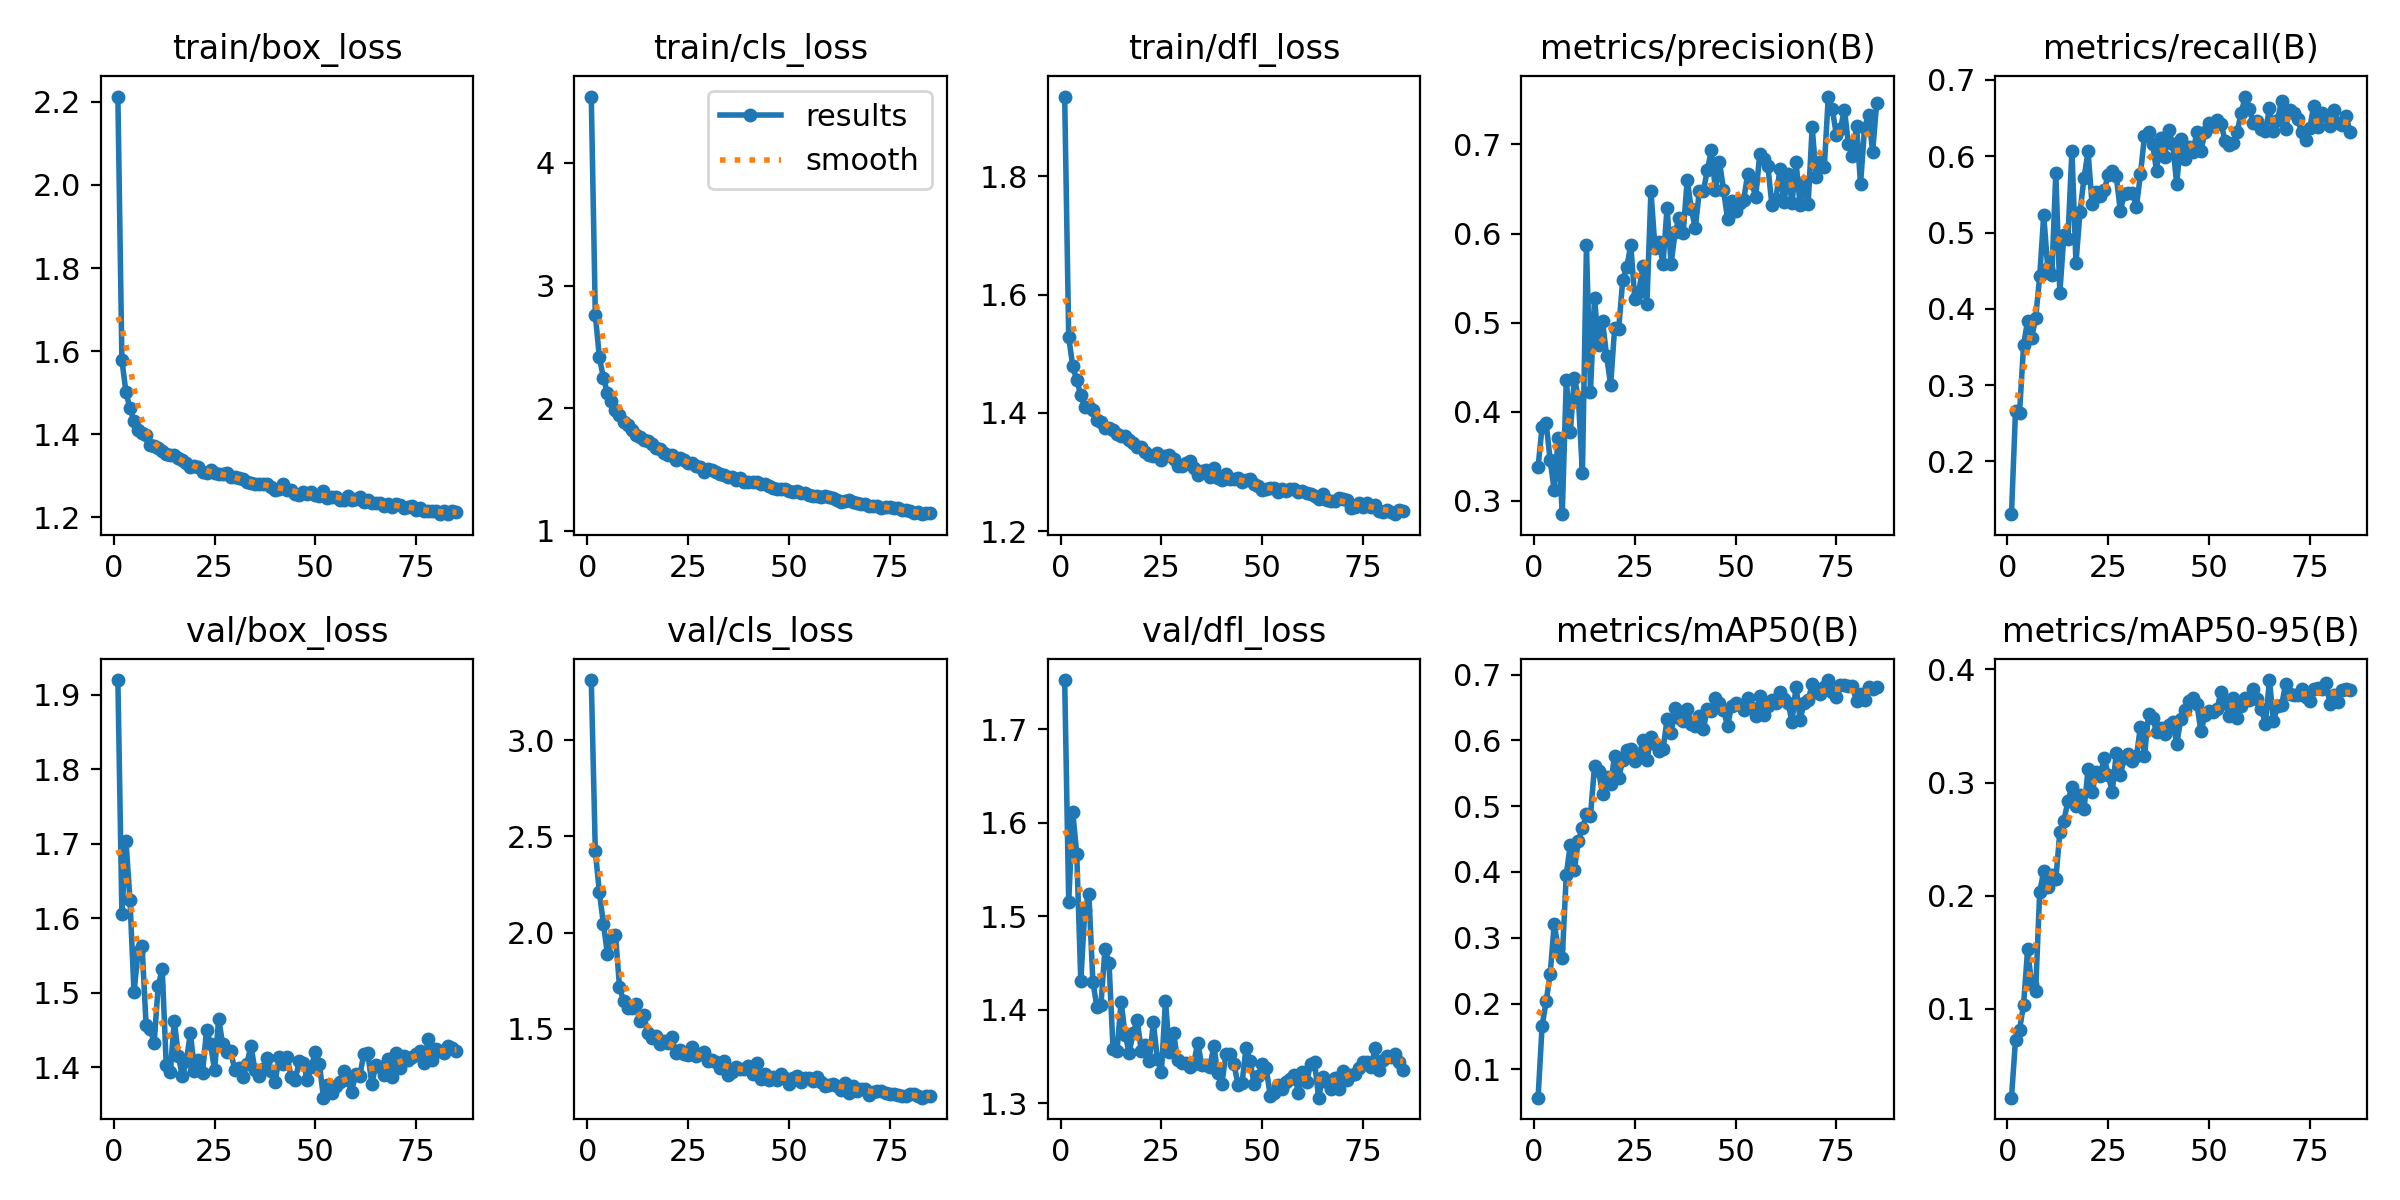

Epochs trained: 85
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    81               0.65549            0.66068           0.67079              0.37696
    82               0.71886            0.64322           0.66110              0.37153
    83               0.73315            0.64073           0.68149              0.38174
    84               0.69205            0.65266           0.67832              0.38309
    85               0.74620            0.63204           0.68125              0.38189


In [6]:
import glob, os
from IPython.display import Image, display
# Ultralytics adds a number to the folder name if it already exists (yolov8n_v12, ...),
# so take the folder the trainer actually used, or else the newest matching folder.
try:
    RUN = str(model.trainer.save_dir)
except (NameError, AttributeError):
    RUN = sorted(glob.glob(f'{PROJECT}/runs/{RUN_NAME}*'), key=os.path.getmtime)[-1]
print('Run folder:', RUN, '->', sorted(os.listdir(RUN)))
display(Image(f'{RUN}/results.png', width=900))

import pandas as pd
hist = pd.read_csv(f'{RUN}/results.csv')
hist.columns = hist.columns.str.strip()
print('Epochs trained:', len(hist))
print(hist[['epoch', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)',
            'metrics/mAP50-95(B)']].tail(5).to_string(index=False))

If Colab disconnects, resume with:
```python
YOLO(f'{PROJECT}/runs/{RUN_NAME}/weights/last.pt').train(resume=True)
```

## 5. Evaluate on the test set

In [7]:
best = YOLO(f'{RUN}/weights/best.pt')
m = best.val(data='/content/data/carescan/data.yaml', split='test', imgsz=640,
             project=f'{PROJECT}/runs', name=f'{RUN_NAME}_test')

print(f'mAP@0.5      : {m.box.map50:.3f}   (target >= 0.85)')
print(f'mAP@0.5:0.95 : {m.box.map:.3f}')
print(f'Precision    : {m.box.mp:.3f}')
print(f'Recall       : {m.box.mr:.3f}')

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,139,268 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1526.0±854.0 MB/s, size: 50.1 KB)
val: Scanning /content/data/carescan/test/labels... 199 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 199/199 2.0Kit/s 0.1s
val: New cache created: /content/data/carescan/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.2it/s 6.0s
                   all        199        977      0.677      0.781      0.746      0.413
               wash_30         62         63      0.599      0.711      0.631      0.318
        wash_30_gentle         15         15      0.376      0.267      0.398      0.259
               wash_40         29         32      0.341      0.531      0.402      0.223
        wash_40_gentle         44         44      0.825      0.751      0.

In [8]:
# Per-class AP@0.5: find the weakest symbols
import pandas as pd
names = best.names
rows = [(names[c], m.box.ap50[i]) for i, c in enumerate(m.box.ap_class_index)]
df = pd.DataFrame(rows, columns=['class', 'AP@0.5']).sort_values('AP@0.5')
df.to_csv(f'{m.save_dir}/per_class_ap.csv', index=False)
df

,class,AP@0.5
17,iron_high,0.280348
13,dry_flat,0.388054
1,wash_30_gentle,0.398034
2,wash_40,0.401737
11,dry_line,0.463409
14,dry_shade,0.497500
0,wash_30,0.630631
9,tumble_normal,0.686010
4,wash_hand,0.843015
3,wash_40_gentle,0.855546


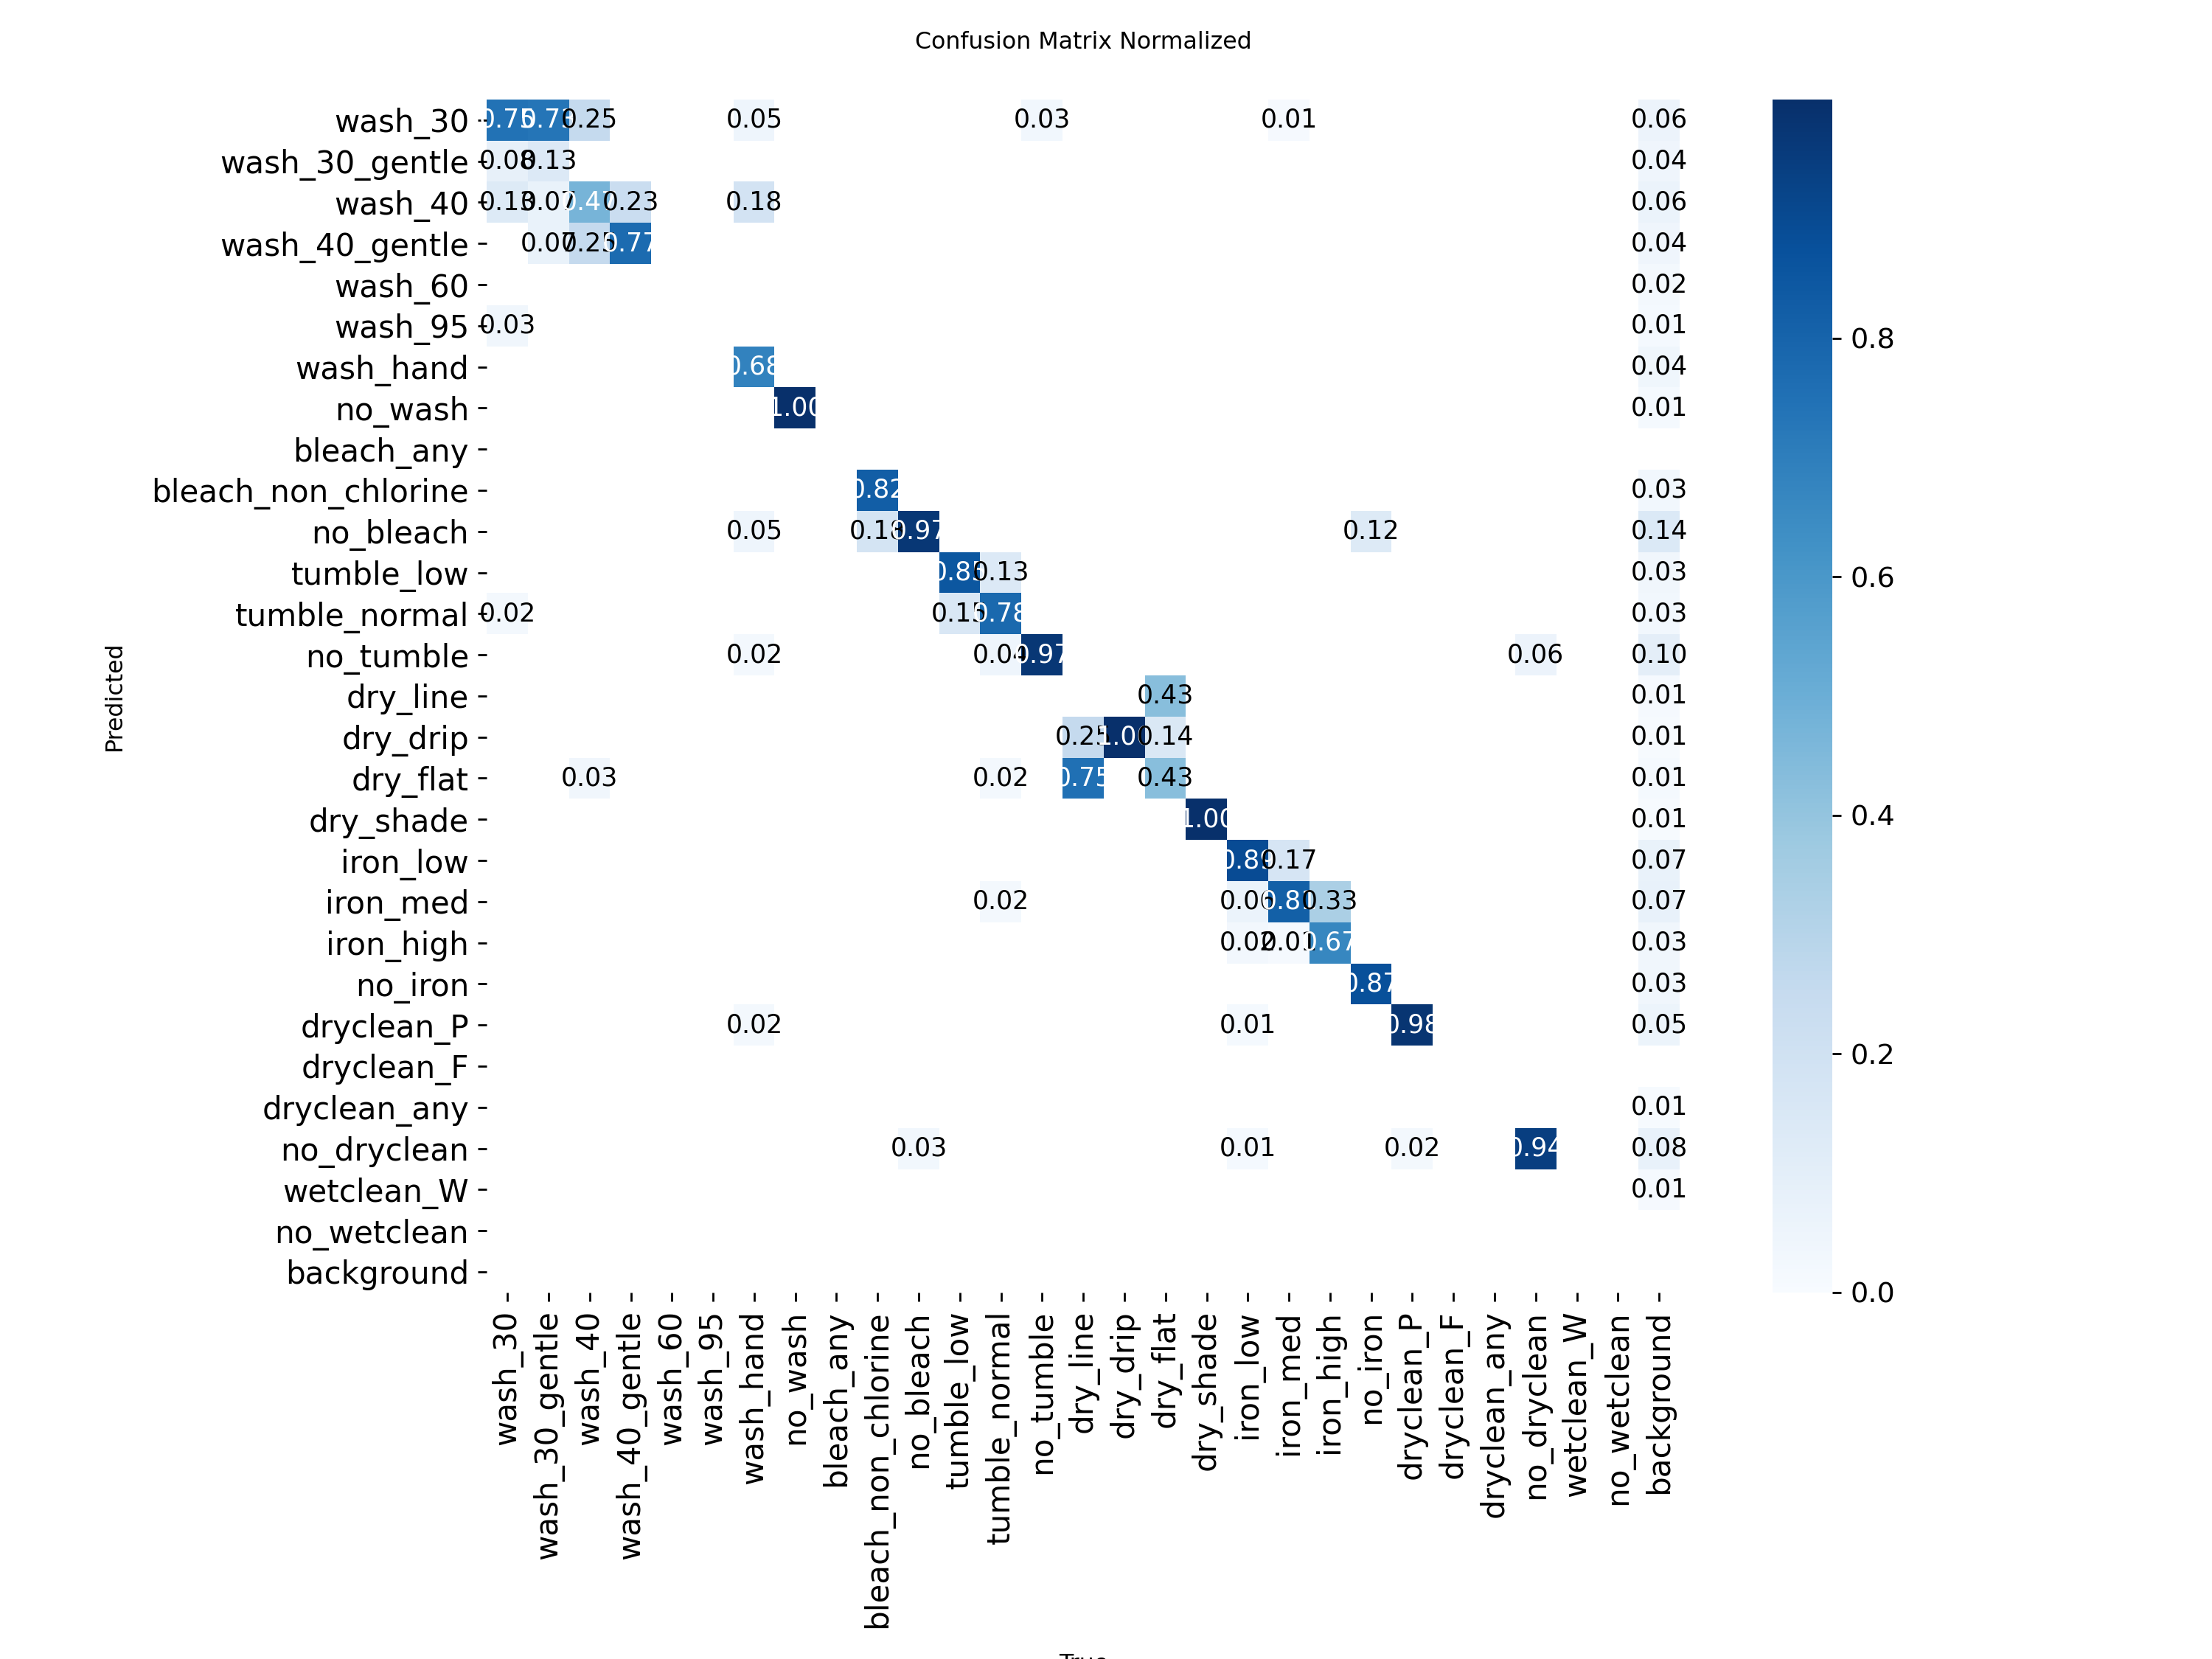

In [9]:
# Confusion matrix: which symbols get mixed up?
display(Image(f'{m.save_dir}/confusion_matrix_normalized.png', width=900))

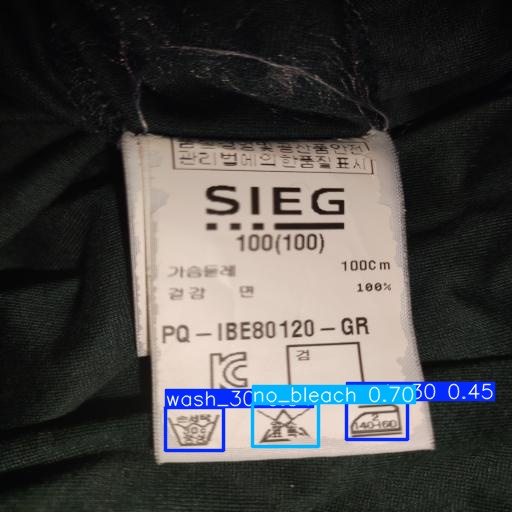

/content/data/carescan/test/images/own__carescan_own_photos_v1__train__1000005057_jpg.rf.b32ff1f12573ab30d99335be1e8f67ff.jpg -> ['no_bleach', 'wash_30', 'wash_30']


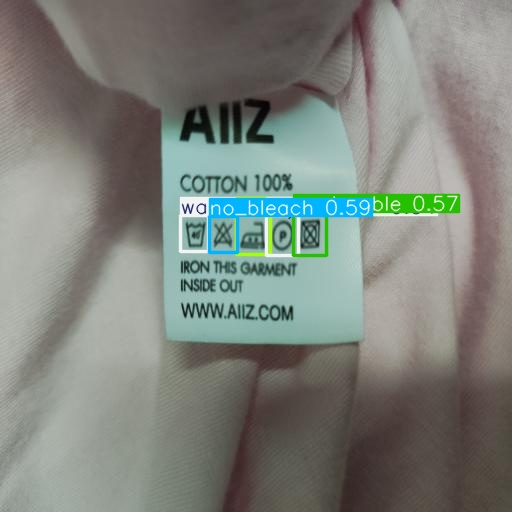

/content/data/carescan/test/images/own__carescan_own_photos_v1__train__1000005065_jpg.rf.6ce69a678586cdb6f219223ecbbe6410.jpg -> ['no_bleach', 'no_tumble', 'dryclean_P', 'iron_med', 'wash_40']


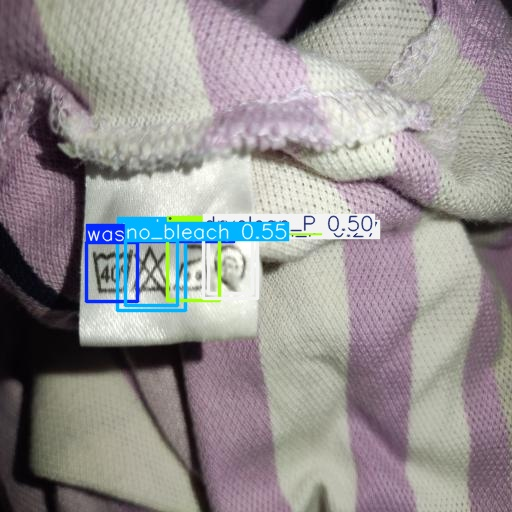

/content/data/carescan/test/images/own__carescan_own_photos_v1__train__1000005059_jpg.rf.fabac1dd2bfed09a6838d86695f3220c.jpg -> ['no_bleach', 'dryclean_P', 'iron_med', 'wash_30', 'no_bleach', 'dryclean_P']


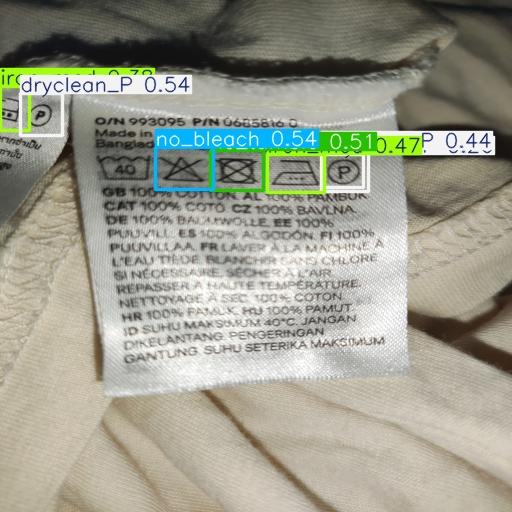

/content/data/carescan/test/images/own__carescan_own_photos_v1__train__1000005058_jpg.rf.8c5c90f8a9470c39cedd2746df000ccd.jpg -> ['dryclean_P', 'no_bleach', 'no_tumble', 'iron_med', 'dryclean_P', 'iron_med', 'dryclean_P']


In [10]:
# Look at predictions on our own test photos
import glob, random, cv2
own_test = sorted(glob.glob('/content/data/carescan/test/images/own__*'))
for p in random.sample(own_test, min(6, len(own_test))):
    r = best.predict(p, conf=0.25, verbose=False)[0]
    display(Image(data=cv2.imencode('.jpg', r.plot())[1].tobytes(), width=500))
    print(p, '->', [names[int(c)] for c in r.boxes.cls])

## 6. Export for the app

Copies `best.pt` into `models/` so the Streamlit app and evaluation script can use it.

In [11]:
import shutil, os
os.makedirs('models', exist_ok=True)
# Keep the first model under its own name before overwriting models/best.pt
if os.path.exists('models/best.pt') and not os.path.exists('models/best_yolov8n_v1.pt'):
    shutil.copy('models/best.pt', 'models/best_yolov8n_v1.pt')
    print('Backed up the previous model as models/best_yolov8n_v1.pt')

shutil.copy(f'{RUN}/weights/best.pt', f'models/best_{RUN_NAME}.pt')   # kept for comparison
shutil.copy(f'{RUN}/weights/best.pt', 'models/best.pt')               # the app uses this one
# Optional faster CPU inference:
# best.export(format='onnx', imgsz=640)
print(f'Saved models/best_{RUN_NAME}.pt and models/best.pt')

Backed up the previous model as models/best_yolov8n_v1.pt
Saved models/best_yolov8n_v2_noleak.pt and models/best.pt


## 7. (Optional) End-to-end evaluation

Runs the full pipeline (preprocess → YOLO → OCR → rules) on our own photos and compares with
`data/ground_truth.csv`. This measures what the user actually gets, including speed.

In [12]:
# Needs data/ground_truth.csv and a folder data/own_photos/ — skip until those exist.
if os.path.exists('data/ground_truth.csv') and os.path.isdir('data/own_photos'):
    !python scripts/evaluate_pipeline.py --model models/best.pt --images data/own_photos --truth data/ground_truth.csv
else:
    print('Skipped: create data/ground_truth.csv and data/own_photos/ first (see README).')

Skipped: create data/ground_truth.csv and data/own_photos/ first (see README).


## Experiment log (fill in for the report)

| Run | Model | imgsz | degrees | Epochs | Train imgs | mAP@0.5 (test) | Notes |
|---|---|---|---|---|---|---|---|
| yolov8n_v1 | v8n | 640 | 180 | 100 | 3,910 | 0.904 | baseline; augmented copies leaked into test; 4 own photos in test |
| yolov8n_v2_noleak | v8n | 640 | 180 | | | | split keeps augmented copies together |
| yolov8n_v3_960 | v8n | 960 | 180 | | | | bigger images for washtub numbers |
| | | | | | | | |